# Práctica guiada — Inferencia y contratos

Este notebook es para el alumnado. Completa las celdas marcadas con `TODO` y responde las preguntas antes de mirar la solución docente.

**Objetivo:** pasar de una fila CSV a una especificación clara para el módulo de inferencia de la clase 2.

## Cómo trabajar

1. Copia esta carpeta como tu espacio de trabajo.
2. Ejecuta `uv sync` desde `problem/starter/` cuando empiece la clase 2.
3. En esta práctica no implementes todavía el CLI completo.
4. Trabaja en parejas y cambia quién escribe cada diez minutos.
5. No abras `solutions/` hasta el debrief.

In [1]:
from dataclasses import dataclass
import csv
from pathlib import Path

from pydantic import BaseModel, ConfigDict, Field, ValidationError

DATA_PATH = Path("../../../../../../assets/03-wine-quality/inference_samples.csv")
print(DATA_PATH)
print(DATA_PATH.exists())

..\..\..\..\..\..\assets\03-wine-quality\inference_samples.csv
True


## 1. Leer los datos nuevos

### Práctica A — Inspección del CSV

Completa la celda siguiente para:

- Leer el CSV con `csv.DictReader`.
- Imprimir el número de filas.
- Imprimir las columnas.
- Guardar la primera fila en una variable llamada `row`.

In [2]:
# TODO: implementa la lectura del CSV.
# Pista: usa DATA_PATH.open(newline="", encoding="utf-8")
# Leo el CSV, cada fila es un diccionario columna -> valor
with DATA_PATH.open(newline="", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    columnas = reader.fieldnames
    rows = list(reader)

row = rows[0]

print("Numero de filas:", len(rows))
print("Columnas:", columnas)
print("Primera fila:", row)



Numero de filas: 5
Columnas: ['sample_id', 'fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol']
Primera fila: {'sample_id': 'red-001', 'fixed_acidity': '7.4', 'volatile_acidity': '0.7', 'citric_acid': '0.0', 'residual_sugar': '1.9', 'chlorides': '0.076', 'free_sulfur_dioxide': '11.0', 'total_sulfur_dioxide': '34.0', 'density': '0.9978', 'ph': '3.51', 'sulphates': '0.56', 'alcohol': '9.4'}


### Preguntas

1. ¿Qué campo identifica la muestra pero no es una característica del modelo?

   El sample_id. Sirve para saber qué muestra es y devolverlo junto a la predicción, pero no es una característica del vino, así que no tiene que entrar al modelo (además es texto y el modelo espera 11 números).

2. ¿Cuántas características numéricas hay?

   Hay 11 (las 12 columnas del CSV menos el sample_id).

3. ¿Qué columna extra añadirías para probar el contrato?

   Una columna inventada como unexpected_field, para ver que el contrato la rechaza. También probaría con quality, que es la etiqueta: en inferencia no la tenemos y no debería poder colarse.

4. ¿Qué valor de `ph` sería claramente inválido?

   Por ejemplo ph = 99, porque el pH va de 0 a 14. Además en nuestro contrato el rango es de 2.5 a 4.5, así que algo como ph = 6 también sería inválido.

## 2. Construir el contrato con Pydantic

El contrato del modelo contiene estas características:

| Campo | Rango orientativo |
|---|---|
| `fixed_acidity` | 0–20 |
| `volatile_acidity` | 0–2 |
| `citric_acid` | 0–2 |
| `residual_sugar` | 0–20 |
| `chlorides` | 0–1 |
| `free_sulfur_dioxide` | 0–100 |
| `total_sulfur_dioxide` | 0–300 |
| `density` | 0.98–1.01 |
| `ph` | 2.5–4.5 |
| `sulphates` | 0–3 |
| `alcohol` | 5–20 |

In [ ]:
class WineQualityRequestPydantic(BaseModel):
    # TODO: prohíbe campos extra con model_config.
    # TODO: declara las 11 características con Field(ge=..., le=...).
    # si llega una columna que no conocemos, error
    model_config = ConfigDict(extra="forbid")

    fixed_acidity: float = Field(ge=0, le=20)
    volatile_acidity: float = Field(ge=0, le=2)
    citric_acid: float = Field(ge=0, le=2)
    residual_sugar: float = Field(ge=0, le=20)
    chlorides: float = Field(ge=0, le=1)
    free_sulfur_dioxide: float = Field(ge=0, le=100)
    total_sulfur_dioxide: float = Field(ge=0, le=300)
    density: float = Field(ge=0.98, le=1.01)
    ph: float = Field(ge=2.5, le=4.5)
    sulphates: float = Field(ge=0, le=3)
    alcohol: float = Field(ge=5, le=20)

# TODO: separa sample_id de la fila y valida solo las características del modelo.
sample_id = row["sample_id"]
model_row = {k: v for k, v in row.items() if k != "sample_id"}

request = WineQualityRequestPydantic.model_validate(model_row)
print(sample_id, request)

# pydantic ha convertido el texto a float
print(type(request.ph))

red-001 fixed_acidity=7.4 volatile_acidity=0.7 citric_acid=0.0 residual_sugar=1.9 chlorides=0.076 free_sulfur_dioxide=11.0 total_sulfur_dioxide=34.0 density=0.9978 ph=3.51 sulphates=0.56 alcohol=9.4
<class 'float'>


### Práctica B — Validación

Completa una prueba para cada caso:

- Una fila válida.
- Una columna `unexpected_field`.
- Un `ph` fuera de rango.

Antes de ejecutar, escribe qué error esperas.

**Lo que espero que pase:**

- Fila válida: no da error, se crea el objeto.
- Columna unexpected_field: ValidationError de tipo extra_forbidden, porque el modelo tiene extra="forbid" y no acepta campos que no estén definidos.
- ph = 99: ValidationError de tipo less_than_equal, porque el máximo es 4.5 (le=4.5).

In [4]:
# TODO: completa los casos y captura ValidationError.
casos = {
    "fila valida": model_row,
    "columna extra": {**model_row, "unexpected_field": "not allowed"},
    "ph fuera de rango": {**model_row, "ph": "99"},
}


for nombre, datos in casos.items():
    try:
        WineQualityRequestPydantic.model_validate(datos)
        print(nombre, "-> OK, es valido")
    except ValidationError as error:
        print(nombre, "-> ERROR")
        for e in error.errors():
            print("   campo:", e["loc"], "| tipo:", e["type"], "|", e["msg"])

fila valida -> OK, es valido
columna extra -> ERROR
   campo: ('unexpected_field',) | tipo: extra_forbidden | Extra inputs are not permitted
ph fuera de rango -> ERROR
   campo: ('ph',) | tipo: less_than_equal | Input should be less than or equal to 4.5


## 3. Comparar con `dataclass`

Construye la misma estructura con `dataclass`. No añadas todavía validación manual: observa qué garantiza Python y qué no garantiza.

In [5]:
@dataclass(frozen=True, slots=True)
class WineQualityRequestDataclass:
    # TODO: declara las mismas 11 características.
    fixed_acidity: float
    volatile_acidity: float
    citric_acid: float
    residual_sugar: float
    chlorides: float
    free_sulfur_dioxide: float
    total_sulfur_dioxide: float
    density: float
    ph: float
    sulphates: float
    alcohol: float

# TODO: crea una instancia válida y prueba qué ocurre con ph=99.0.
# 1. instancia "valida" con los datos del csv
dc = WineQualityRequestDataclass(**model_row)
print(dc)
print("tipo de ph:", type(dc.ph)) 

# 2. ph = 99.0
dc_mal = WineQualityRequestDataclass(**{**model_row, "ph": 99.0})
print("ph = 99 aceptado:", dc_mal.ph) 

# 3. columna extra
try:
    WineQualityRequestDataclass(**model_row, unexpected_field="x")
except TypeError as error:
    print("TypeError:", error)

WineQualityRequestDataclass(fixed_acidity='7.4', volatile_acidity='0.7', citric_acid='0.0', residual_sugar='1.9', chlorides='0.076', free_sulfur_dioxide='11.0', total_sulfur_dioxide='34.0', density='0.9978', ph='3.51', sulphates='0.56', alcohol='9.4')
tipo de ph: <class 'str'>
ph = 99 aceptado: 99.0
TypeError: WineQualityRequestDataclass.__init__() got an unexpected keyword argument 'unexpected_field'


### Decisión de diseño

Completa la frase:

> Usaría Pydantic en la entrada de datos que vienen de fuera de nuestro programa porque convierte los tipos, comprueba los rangos y rechaza columnas no existentes. Usaría dataclass en estructuras propias cuyos datos ya se han validado antes, ya que es mas ligera.

## 4. Definir el orden del vector

El modelo no recibe un diccionario. Recibe una lista numérica con un orden estable.

In [6]:
# TODO: rellena el orden exacto a partir del CSV y del contrato.
FEATURE_NAMES = (
    "fixed_acidity",
    "volatile_acidity",
    "citric_acid",
    "residual_sugar",
    "chlorides",
    "free_sulfur_dioxide",
    "total_sulfur_dioxide",
    "density",
    "ph",
    "sulphates",
    "alcohol",
)

# TODO: construye vector usando getattr(request, name).
# vector = [...]

vector = []
for name in FEATURE_NAMES:
    valor = getattr(request, name)
    vector.append(valor)


print(vector)


[7.4, 0.7, 0.0, 1.9, 0.076, 11.0, 34.0, 0.9978, 3.51, 0.56, 9.4]


### Práctica C — Error de orden

Intercambia mentalmente `density` y `alcohol`. Responde:

- ¿El vector sigue teniendo 11 valores?

  Sí, sigue teniendo 11 valores y todos son números. Solo cambian de sitio dos de ellos, así que a simple vista parece correcto.

- ¿El clasificador detectaría necesariamente el error?

  No. El modelo solo ve números por posición, no sabe cómo se llama cada uno. Pondría 9.4 (el alcohol) donde espera la densidad y 0.9978 (la densidad) donde espera el alcohol, y devolvería una predicción igualmente, sin dar ningún error, pero estaría mal. Es el peor tipo de fallo porque es silencioso.

- ¿Cómo evitarías que cada script definiera un orden distinto?

  1. Definir FEATURE_NAMES una sola vez (en preprocess.py) e importarlo desde todos los sitios.
  2. Hacer un test que compruebe el orden del vector.

In [ ]:
# demostracion: cambio density y alcohol de sitio
orden_mal = list(FEATURE_NAMES)
i = orden_mal.index("density")
j = orden_mal.index("alcohol")
orden_mal[i], orden_mal[j] = orden_mal[j], orden_mal[i]

vector_mal = []
for name in orden_mal:
    vector_mal.append(getattr(request, name))

print("bien:", vector)
print("mal: ", vector_mal)
print("longitud:", len(vector), len(vector_mal)) 

assert len(vector_mal) == 11     
assert vector_mal != vector       

bien: [7.4, 0.7, 0.0, 1.9, 0.076, 11.0, 34.0, 0.9978, 3.51, 0.56, 9.4]
mal:  [7.4, 0.7, 0.0, 1.9, 0.076, 11.0, 34.0, 9.4, 3.51, 0.56, 0.9978]
longitud: 11 11


## 5. Contrato de salida

Diseña la estructura que devolverá el módulo. Debe permitir responder:

- ¿Qué muestra se ha procesado?
- ¿Qué categoría se ha predicho?
- ¿Con qué confianza?
- ¿Qué versión de modelo y preprocesado se utilizaron?

In [8]:
from typing import Literal

QualityBand = Literal["needs_review", "acceptable", "excellent"]


class WineQualityPredictionPydantic(BaseModel):
    # TODO: declara los campos de salida y sus restricciones.
    model_config = ConfigDict(extra="forbid")
    
    sample_id: str = Field(min_length=1)
    quality_band: QualityBand
    confidence: float = Field(ge=0, le=1)
    model_version: str = Field(min_length=1)
    preprocessing_version: str = Field(min_length=1)

# TODO: escribe un ejemplo de salida para red-001.
# ejemplo de salida para red-001
ejemplo = WineQualityPredictionPydantic(
    sample_id="red-001",
    quality_band="needs_review",
    confidence=0.77,
    model_version="wine-quality-rf-v1",
    preprocessing_version="wine-red-features-v1",
)
print(ejemplo.model_dump())

{'sample_id': 'red-001', 'quality_band': 'needs_review', 'confidence': 0.77, 'model_version': 'wine-quality-rf-v1', 'preprocessing_version': 'wine-red-features-v1'}


## 6. Demo del docente: observar la inferencia

El docente ejecutará el notebook resuelto y el comando de referencia. Mientras tanto, anota el recorrido:

```text
CSV → contrato → preprocesado → modelo cargado → predicción
```

No copies la implementación. Tu código de producción empieza en la clase 2 con el starter.

**Recorrido de red-001:**

```text
CSV (fila en texto, 12 columnas)
  - quito sample_id y lo guardo aparte para la salida
  - contrato de entrada (Pydantic): convierte a float, comprueba rangos y que no haya columnas extra
  - preprocesado: vector de 11 números en el orden de FEATURE_NAMES
  - modelo cargado: antes se comprueba que sus feature_names coinciden con FEATURE_NAMES
  - predicción: categoría + confianza (needs_review, 0.77)
  - contrato de salida: sample_id, quality_band, confidence, model_version, preprocessing_version
  - CSV de salida (solo se escribe si todas las filas son válidas)
```

Si añado una columna unexpected_field al CSV, falla en el paso del contrato de entrada, antes de llegar al modelo, y no se crea el CSV de salida.

## Entrega

Entrega una captura o exportación con:

- La tabla de contrato.
- Las respuestas de las prácticas A, B y C.
- El orden de las 11 características.
- Un ejemplo de entrada inválida.
- Un contrato de salida.
- Tu plan de implementación para `contracts.py`, `preprocess.py`, `inference.py` y `predict_file.py`.

## Contrato y preprocesado

### 1. Entrenamiento, artefacto y datos nuevos

- **Datos de entrenamiento:** el CSV completo de Red Wine Quality.
- **Artefacto:** models/wine_quality_classifier.joblib. Es el modelo ya entrenado guardado en disco, junto con los feature_names (el orden con el que se entrenó) y su model_version.
- **Datos nuevos:** inference_samples.csv, 5 vinos sin la columna quality. Son los que queremos predecir.

### 2. Tabla del contrato de entrada

| Campo | Tipo | Unidad | Límite | ¿Acepta ausentes? |
|---|---|---|---|---|
| fixed_acidity | float | g/dm3 (ácido tartárico) | 0 – 20 | No |
| volatile_acidity | float | g/dm3 (ácido acético) | 0 – 2 | No |
| citric_acid | float | g/dm3 | 0 – 2 | No |
| residual_sugar | float | g/dm3 | 0 – 20 | No |
| chlorides | float | g/dm3 (cloruro sódico) | 0 – 1 | No |
| free_sulfur_dioxide | float | mg/dm3 | 0 – 100 | No |
| total_sulfur_dioxide | float | mg/dm3 | 0 – 300 | No |
| density | float | g/cm3 | 0.98 – 1.01 | No |
| ph | float | sin unidad | 2.5 – 4.5 | No |
| sulphates | float | g/dm3 (sulfato potásico) | 0 – 3 | No |
| alcohol | float | % vol. | 5 – 20 | No |

Ningún campo admite valores ausentes: el modelo necesita los 11 números y no hay una regla de imputación definida. Si falta uno, Pydantic da error missing.

No aceptmos columnas extra. El sample_id es obligatorio en el CSV pero no forma parte del contrato del modelo.

### 3. Casos de entrada y dónde falla cada uno

| Caso | Fila | ¿Pasa? | ¿Por qué? |
|---|---|---|---|
| Válida | red-001,7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4 | Sí | No se rechaza, genera predicción |
| Columna desconocida | la misma fila con una columna más unexpected_field=not allowed | No | En el **contrato de entrada** (extra_forbidden), antes del preprocesado |
| Fuera de rango | la misma fila con ph=99 | No | En el **contrato de entrada** (less_than_equal, máximo 4.5), antes del preprocesado |

En todos los casos de fallo el script tiene que parar sin crear el CSV de salida.

### 4. Orden del vector

fixed_acidity, volatile_acidity, citric_acid, residual_sugar, chlorides, free_sulfur_dioxide, total_sulfur_dioxide, density, ph, sulphates, alcohol

Es el orden con el que se entrenó el modelo.

### 5. Criterios de aceptación para el script de la clase 2

1. Una fila válida genera una predicción con sample_id, categoría, confianza y las dos versiones (model_version y preprocessing_version).
2. Si hay una columna extra, falta un campo o un valor está fuera de rango, el script para con un error claro que dice la fila y el campo, y no crea el CSV de salida (aunque las filas anteriores fueran válidas).
3. Si el modelo tiene los feature_names en otro orden o le falta el estimador, el script lo rechaza antes de predecir.

### Plan de implementación

- **contracts.py (validar):** el contrato de entrada WineQualityRequest (las 11 features con sus rangos y extra="forbid") y el de salida WineQualityPrediction (categoría con Literal, confianza entre 0 y 1 y las dos versiones).
- **preprocess.py (preprocesar):** FEATURE_NAMES con el orden fijo, la versión del preprocesado y la función que pasa del request validado al vector de 11 números. No lee el CSV.
- **inference.py (inferir):** cargar el .joblib y comprobar que está bien antes de usarlo (que tiene el estimador, la versión y que los feature_names coinciden con FEATURE_NAMES). Después predecir la categoría y la confianza con predict y predict_proba.
- **predict_file.py (orquestar el fichero):** el script que lo une todo. Lee el CSV, valida cada fila, preprocesa, predice y escribe el CSV de salida al final. Si alguna fila falla, sale con un error clro y no deja nada a medias.

**Orden de implementación:** primero contracts, luego preprocess, luego inference y al final predict_file, porque cada uno usa el anterior.

**Diagrama**

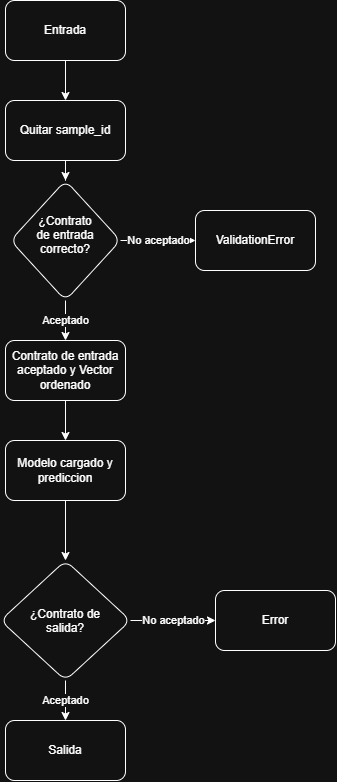